In [1]:

import pandas as pd
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

df = pd.read_csv("netflix_titles.csv")

print(df.head())
print("Dataset shape:", df.shape)


  show_id     type                  title         director  \
0      s1    Movie   Dick Johnson Is Dead  Kirsten Johnson   
1      s2  TV Show          Blood & Water              NaN   
2      s3  TV Show              Ganglands  Julien Leclercq   
3      s4  TV Show  Jailbirds New Orleans              NaN   
4      s5  TV Show           Kota Factory              NaN   

                                                cast        country  \
0                                                NaN  United States   
1  Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...   South Africa   
2  Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...            NaN   
3                                                NaN            NaN   
4  Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...          India   

           date_added  release_year rating   duration  \
0  September 25, 2021          2020  PG-13     90 min   
1  September 24, 2021          2021  TV-MA  2 Seasons   
2  September 24, 2021        

In [3]:

conn = sqlite3.connect("netflix.db")

df.to_sql(
    "netflix_titles",
    conn,
    if_exists="replace",
    index=False
)

print("Netflix data stored in SQL database!")


Netflix data stored in SQL database!


In [5]:

query = """
SELECT type, COUNT(*) AS total_titles
FROM netflix_titles
GROUP BY type;
"""

result = pd.read_sql_query(query, conn)

print(result)


      type  total_titles
0    Movie          6131
1  TV Show          2676


In [6]:

import pandas as pd
import sqlite3

conn = sqlite3.connect("netflix.db")

check = pd.read_sql_query(
    "SELECT name FROM sqlite_master WHERE type='table';",
    conn
)

print(check)


             name
0  netflix_titles


In [7]:

query = """
SELECT COUNT(*) AS total_titles
FROM netflix_titles
WHERE country LIKE '%India%';
"""

result = pd.read_sql_query(query, conn)
print(result)


   total_titles
0          1046


In [8]:

query = """
SELECT rating, COUNT(*) AS total_titles
FROM netflix_titles
WHERE rating IS NOT NULL
GROUP BY rating
ORDER BY total_titles DESC
LIMIT 10;
"""

result = pd.read_sql_query(query, conn)
print(result)


  rating  total_titles
0  TV-MA          3207
1  TV-14          2160
2  TV-PG           863
3      R           799
4  PG-13           490
5  TV-Y7           334
6   TV-Y           307
7     PG           287
8   TV-G           220
9     NR            80


In [13]:

query = """
SELECT release_year, COUNT(*) AS total_titles
FROM netflix_titles
WHERE release_year IS NOT NULL
GROUP BY release_year
ORDER BY release_year DESC
LIMIT 15;
"""

result = pd.read_sql_query(query, conn)

print(result.head())
print(result.columns)


   release_year  total_titles
0          2021           592
1          2020           953
2          2019          1030
3          2018          1147
4          2017          1032
Index(['release_year', 'total_titles'], dtype='object')


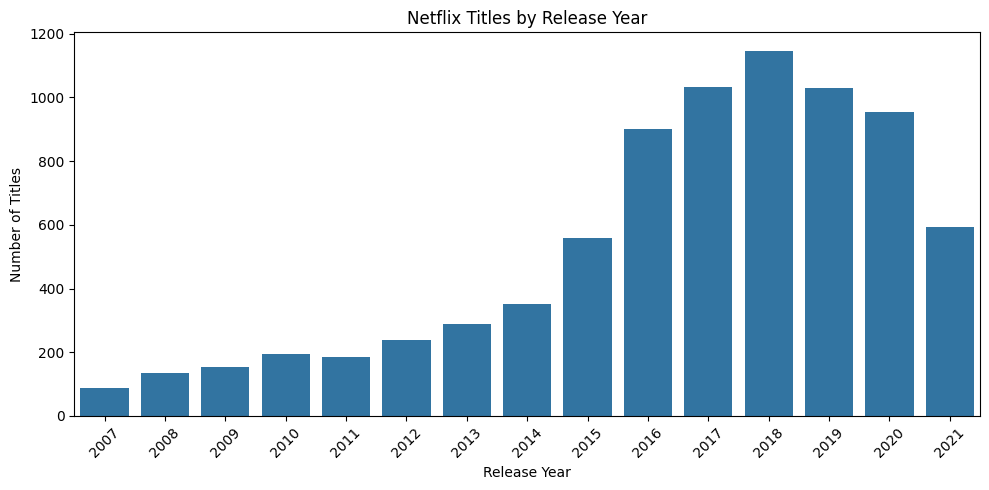

In [14]:

plt.figure(figsize=(10, 5))

sns.barplot(
    data=result,
    x="release_year",
    y="total_titles"
)

plt.title("Netflix Titles by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [15]:

query = """
SELECT country, COUNT(*) AS total_titles
FROM netflix_titles
WHERE country IS NOT NULL
GROUP BY country
ORDER BY total_titles DESC
LIMIT 10;
"""

country_result = pd.read_sql_query(query, conn)

print(country_result)


          country  total_titles
0   United States          2818
1           India           972
2  United Kingdom           419
3           Japan           245
4     South Korea           199
5          Canada           181
6           Spain           145
7          France           124
8          Mexico           110
9           Egypt           106


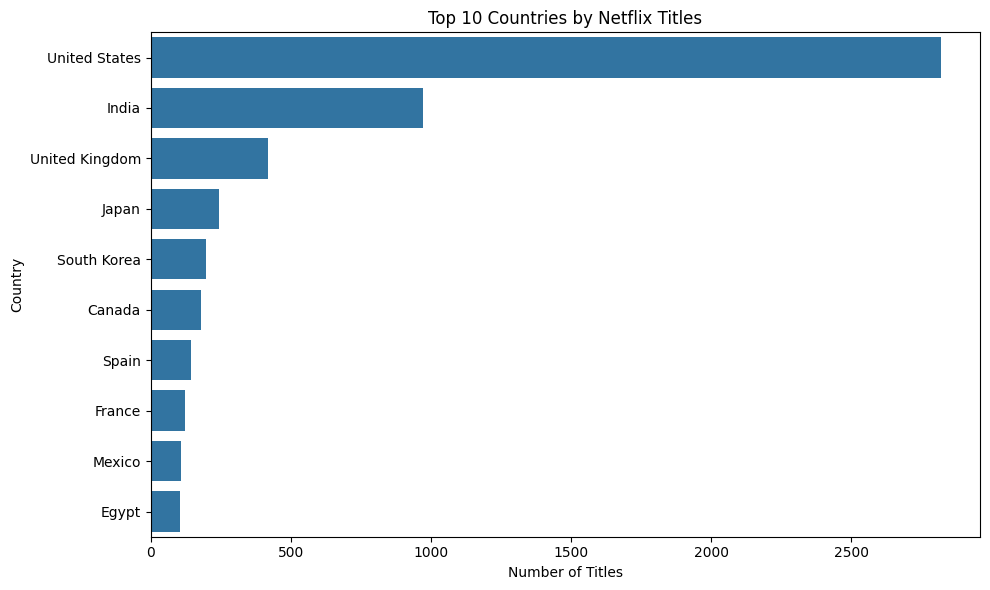

In [16]:

plt.figure(figsize=(10, 6))

sns.barplot(
    data=country_result,
    x="total_titles",
    y="country"
)

plt.title("Top 10 Countries by Netflix Titles")
plt.xlabel("Number of Titles")
plt.ylabel("Country")
plt.tight_layout()
plt.show()


In [17]:

query = """
SELECT rating, COUNT(*) AS total_titles
FROM netflix_titles
WHERE rating IS NOT NULL
GROUP BY rating
ORDER BY total_titles DESC
LIMIT 10;
"""

rating_result = pd.read_sql_query(query, conn)
print(rating_result)


  rating  total_titles
0  TV-MA          3207
1  TV-14          2160
2  TV-PG           863
3      R           799
4  PG-13           490
5  TV-Y7           334
6   TV-Y           307
7     PG           287
8   TV-G           220
9     NR            80


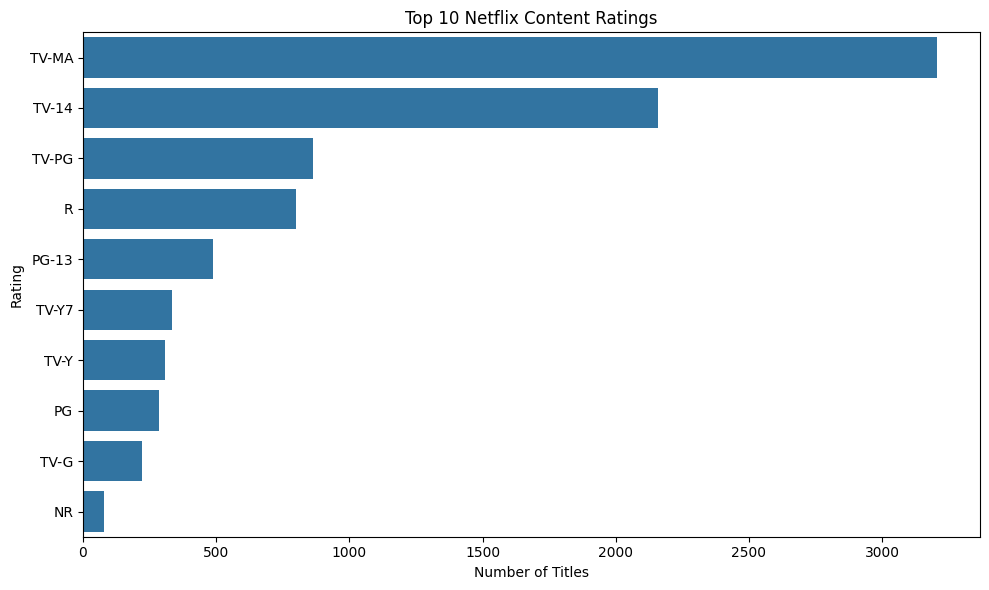

In [18]:

plt.figure(figsize=(10, 6))

sns.barplot(
    data=rating_result,
    x="total_titles",
    y="rating"
)

plt.title("Top 10 Netflix Content Ratings")
plt.xlabel("Number of Titles")
plt.ylabel("Rating")
plt.tight_layout()
plt.show()


In [19]:

query = """
SELECT
    SUM(CASE WHEN listed_in LIKE '%Dramas%'
        THEN 1 ELSE 0 END) AS dramas,
    SUM(CASE WHEN listed_in LIKE '%Comedies%'
        THEN 1 ELSE 0 END) AS comedies,
    SUM(CASE WHEN listed_in LIKE '%Documentaries%'
        THEN 1 ELSE 0 END) AS documentaries,
    SUM(CASE WHEN listed_in LIKE '%International TV Shows%'
        THEN 1 ELSE 0 END) AS international_tv_shows,
    SUM(CASE WHEN listed_in LIKE '%Children%'
        THEN 1 ELSE 0 END) AS children_titles
FROM netflix_titles;
"""

genre_result = pd.read_sql_query(query, conn)
print(genre_result)


   dramas  comedies  documentaries  international_tv_shows  children_titles
0    3190      2255            869                    1351              641


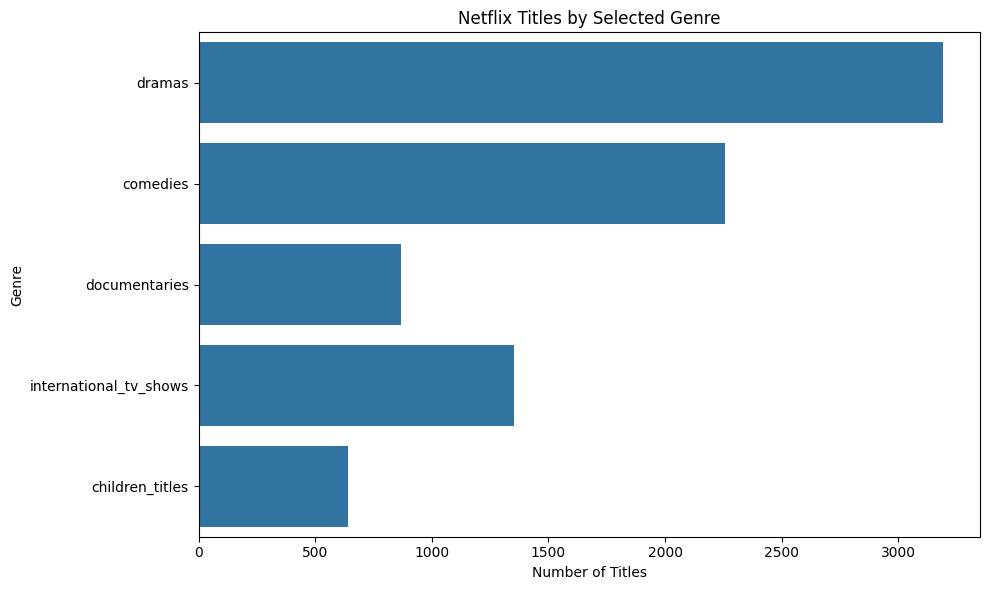

In [20]:

genre_chart = genre_result.T.reset_index()
genre_chart.columns = ["genre", "total_titles"]

plt.figure(figsize=(10, 6))

sns.barplot(
    data=genre_chart,
    x="total_titles",
    y="genre"
)

plt.title("Netflix Titles by Selected Genre")
plt.xlabel("Number of Titles")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()


In [21]:

create_table_query = """
CREATE TABLE IF NOT EXISTS content_summary AS
SELECT
    show_id,
    title,
    type,
    release_year
FROM netflix_titles;
"""

conn.execute(create_table_query)
conn.commit()

print("Content summary table created!")


Content summary table created!


In [22]:

query = """
SELECT
    n.title,
    n.type,
    n.country,
    c.release_year
FROM netflix_titles AS n
JOIN content_summary AS c
    ON n.show_id = c.show_id
LIMIT 10;
"""

join_result = pd.read_sql_query(query, conn)
print(join_result)


                              title     type  \
0              Dick Johnson Is Dead    Movie   
1                     Blood & Water  TV Show   
2                         Ganglands  TV Show   
3             Jailbirds New Orleans  TV Show   
4                      Kota Factory  TV Show   
5                     Midnight Mass  TV Show   
6  My Little Pony: A New Generation    Movie   
7                           Sankofa    Movie   
8     The Great British Baking Show  TV Show   
9                      The Starling    Movie   

                                             country  release_year  
0                                      United States          2020  
1                                       South Africa          2021  
2                                               None          2021  
3                                               None          2021  
4                                              India          2021  
5                                               None     

In [23]:

query = """
SELECT release_year, COUNT(*) AS total_titles
FROM netflix_titles
WHERE release_year IS NOT NULL
GROUP BY release_year
HAVING COUNT(*) > (
    SELECT AVG(yearly_count)
    FROM (
        SELECT COUNT(*) AS yearly_count
        FROM netflix_titles
        WHERE release_year IS NOT NULL
        GROUP BY release_year
    )
)
ORDER BY total_titles DESC;
"""

subquery_result = pd.read_sql_query(query, conn)
print(subquery_result.head(10))


   release_year  total_titles
0          2018          1147
1          2017          1032
2          2019          1030
3          2020           953
4          2016           902
5          2021           592
6          2015           560
7          2014           352
8          2013           288
9          2012           237


In [24]:

conn.execute("""
CREATE TABLE IF NOT EXISTS title_countries (
    show_id TEXT,
    country TEXT
);
""")

conn.execute("DELETE FROM title_countries;")

conn.execute("""
INSERT INTO title_countries (show_id, country)
SELECT
    n.show_id,
    TRIM(c.value)
FROM netflix_titles AS n,
     json_each(
         '["' || REPLACE(
             REPLACE(COALESCE(n.country, ''), '"', '\\"'),
             ', ', '","'
         ) || '"]'
     ) AS c
WHERE TRIM(c.value) <> '';
""")

conn.commit()

print("Country table created!")


Country table created!


In [25]:

query = """
SELECT *
FROM title_countries
LIMIT 10;
"""

country_table = pd.read_sql_query(query, conn)
print(country_table)


  show_id         country
0      s1   United States
1      s2    South Africa
2      s5           India
3      s8   United States
4      s8           Ghana
5      s8    Burkina Faso
6      s8  United Kingdom
7      s8         Germany
8      s8        Ethiopia
9      s9  United Kingdom


In [26]:

query = """
SELECT
    country,
    COUNT(DISTINCT show_id) AS total_titles
FROM title_countries
GROUP BY country
ORDER BY total_titles DESC
LIMIT 10;
"""

country_result = pd.read_sql_query(query, conn)
print(country_result)


          country  total_titles
0   United States          3689
1           India          1046
2  United Kingdom           804
3          Canada           445
4          France           393
5           Japan           318
6           Spain           232
7     South Korea           231
8         Germany           226
9          Mexico           169


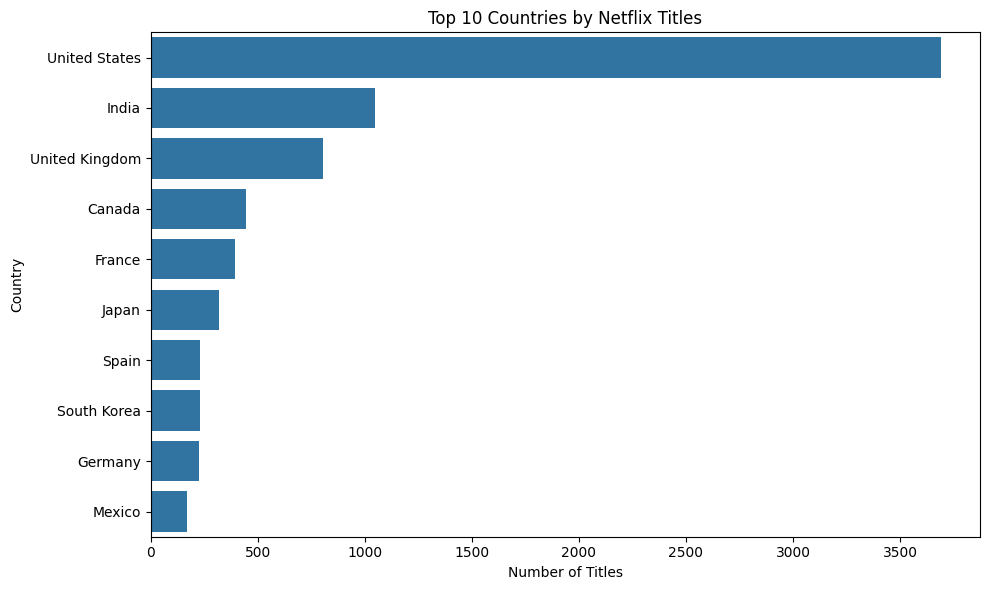

In [27]:

plt.figure(figsize=(10, 6))

sns.barplot(
    data=country_result,
    x="total_titles",
    y="country"
)

plt.title("Top 10 Countries by Netflix Titles")
plt.xlabel("Number of Titles")
plt.ylabel("Country")
plt.tight_layout()
plt.show()


In [28]:

conn.execute("""
CREATE TABLE IF NOT EXISTS title_genres (
    show_id TEXT,
    genre TEXT
);
""")

conn.execute("DELETE FROM title_genres;")

genre_rows = []

for _, row in df[["show_id", "listed_in"]].iterrows():
    if pd.notna(row["listed_in"]):
        for genre in row["listed_in"].split(","):
            genre_rows.append(
                (row["show_id"], genre.strip())
            )

conn.executemany("""
INSERT INTO title_genres (show_id, genre)
VALUES (?, ?);
""", genre_rows)

conn.commit()

print("Genre table created successfully!")


Genre table created successfully!


In [29]:

query = """
SELECT
    genre,
    COUNT(DISTINCT show_id) AS total_titles
FROM title_genres
GROUP BY genre
ORDER BY total_titles DESC
LIMIT 10;
"""

genre_result = pd.read_sql_query(query, conn)
print(genre_result)


                      genre  total_titles
0      International Movies          2752
1                    Dramas          2427
2                  Comedies          1674
3    International TV Shows          1351
4             Documentaries           869
5        Action & Adventure           859
6                 TV Dramas           763
7        Independent Movies           756
8  Children & Family Movies           641
9           Romantic Movies           616


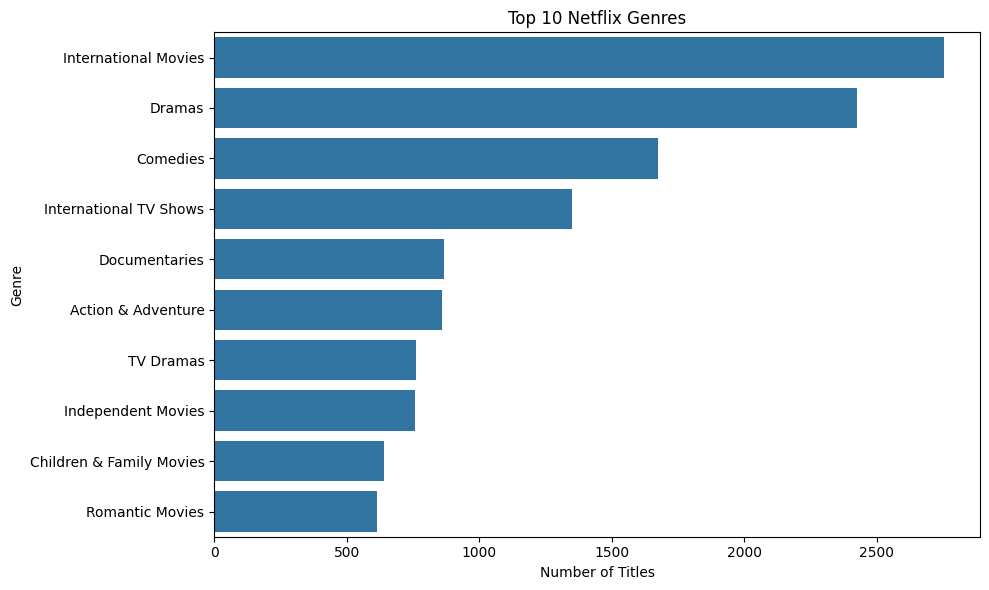

In [30]:

plt.figure(figsize=(10, 6))

sns.barplot(
    data=genre_result,
    x="total_titles",
    y="genre"
)

plt.title("Top 10 Netflix Genres")
plt.xlabel("Number of Titles")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()


In [31]:

query = """
SELECT
    g.genre,
    COUNT(DISTINCT n.show_id) AS total_titles
FROM netflix_titles AS n
JOIN title_genres AS g
    ON n.show_id = g.show_id
WHERE n.release_year >= 2020
GROUP BY g.genre
ORDER BY total_titles DESC
LIMIT 10;
"""

recent_genres = pd.read_sql_query(query, conn)
print(recent_genres)


                      genre  total_titles
0      International Movies           380
1    International TV Shows           363
2                    Dramas           287
3                 TV Dramas           210
4                  Comedies           203
5               TV Comedies           177
6            Crime TV Shows           134
7                Docuseries           131
8             Documentaries           130
9  Children & Family Movies           123


In [32]:

summary_query = """
SELECT
    COUNT(*) AS total_titles,
    SUM(CASE WHEN type = 'Movie' THEN 1 ELSE 0 END) AS total_movies,
    SUM(CASE WHEN type = 'TV Show' THEN 1 ELSE 0 END) AS total_tv_shows,
    COUNT(DISTINCT release_year) AS distinct_release_years,
    COUNT(DISTINCT rating) AS distinct_ratings
FROM netflix_titles;
"""

summary = pd.read_sql_query(summary_query, conn)
display(summary)


,total_titles,total_movies,total_tv_shows,distinct_release_years,distinct_ratings
0,8807,6131,2676,74,17


In [33]:

top_genres_query = """
SELECT
    genre,
    COUNT(DISTINCT show_id) AS total_titles
FROM title_genres
GROUP BY genre
ORDER BY total_titles DESC
LIMIT 5;
"""

top_genres = pd.read_sql_query(top_genres_query, conn)
display(top_genres)


,genre,total_titles
0,International Movies,2752
1,Dramas,2427
2,Comedies,1674
3,International TV Shows,1351
4,Documentaries,869


In [34]:

top_countries_query = """
SELECT
    country,
    COUNT(DISTINCT show_id) AS total_titles
FROM title_countries
GROUP BY country
ORDER BY total_titles DESC
LIMIT 5;
"""

top_countries = pd.read_sql_query(top_countries_query, conn)
display(top_countries)


,country,total_titles
0,United States,3689
1,India,1046
2,United Kingdom,804
3,Canada,445
4,France,393


In [35]:

summary.to_csv("netflix_summary.csv", index=False)
top_genres.to_csv("netflix_top_genres.csv", index=False)
top_countries.to_csv("netflix_top_countries.csv", index=False)

print("Analysis results exported successfully!")


Analysis results exported successfully!


In [36]:

from google.colab import files

files.download("netflix.db")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [39]:

from google.colab import files

files.download("netflix.db")
files.download("netflix_summary.csv")
files.download("netflix_top_genres.csv")
files.download("netflix_top_countries.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>